# RBI Repo Rate vs Bank Lending Trend Analysis

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.0
Seaborn: 0.13.2


In [2]:
print("RBI Repo Rate vs Bank Lending Trend Analysis")
print("Project Setup Successful")

RBI Repo Rate vs Bank Lending Trend Analysis
Project Setup Successful



## 2. Load the Datasets

In [13]:
repo_path = "../data/RBI_Monetary_Policy_Rates.xlsx"
walr_path = "../data/RBI_WALR_Outstanding_Loans.xlsx"

repo_df = pd.read_excel(repo_path)
walr_df = pd.read_excel(walr_path)

print("Repo Rate Data:")
display(repo_df.head())

print("\nWALR Data:")
display(walr_df.head())

Repo Rate Data:


c:\Users\adity\anaconda3\envs\eda\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,NaN,Major Monetary Policy Rates and Reserve Requir...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,(Per cent),NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Effective Date\n,Bank Rate,Fix Range LAF Rates,NaN,Standing Deposit Facility (SDF) Rate,Marginal Standing Facility (MSF) Rate,Cash Reserve Ratio (CRR),Statutory Liquidity Ratio (SLR)



WALR Data:


,Month,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs
0,2012-03-01,12.63,12.41,12.08,12.56
1,2012-06-01,12.39,12.47,12.23,12.40
2,2012-09-01,12.29,12.59,11.87,12.33
3,2012-12-01,12.21,12.43,11.73,12.23
4,2013-03-01,12.11,12.39,12.58,12.19


## 3. Clean and Prepare Repo Rate Data

In [14]:
# Read Repo Rate Excel without assuming a header
repo_raw = pd.read_excel(repo_path, header=None)

# Select actual table data
repo_df = repo_raw.iloc[8:, 1:9].copy()

# Set proper column names
repo_df.columns = [
    "Effective Date",
    "Bank Rate",
    "Repo",
    "Reverse Repo",
    "SDF Rate",
    "MSF Rate",
    "CRR",
    "SLR"
]

# Convert date
repo_df["Effective Date"] = pd.to_datetime(
    repo_df["Effective Date"],
    errors="coerce"
)

# Convert Repo Rate to numeric
repo_df["Repo"] = pd.to_numeric(
    repo_df["Repo"],
    errors="coerce"
)

# Remove rows where date or Repo Rate is missing
repo_df = repo_df.dropna(
    subset=["Effective Date", "Repo"]
).reset_index(drop=True)

display(repo_df.head(10))

c:\Users\adity\anaconda3\envs\eda\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Effective Date,Bank Rate,Repo,Reverse Repo,SDF Rate,MSF Rate,CRR,SLR
0,2025-12-05,5.5,5.25,-,5,5.5,-,-
1,2025-06-06,5.75,5.50,-,5.25,5.75,-,-
2,2025-04-09,6.25,6.00,-,5.75,6.25,-,-
3,2025-02-07,6.5,6.25,-,6,6.5,-,-
4,2023-02-08,6.75,6.50,-,6.25,6.75,-,-
5,2022-12-07,6.5,6.25,-,6,6.5,-,-
6,2022-09-30,6.15,5.90,-,5.65,6.15,-,-
7,2022-08-05,5.65,5.40,-,5.15,5.65,-,-
8,2022-06-08,5.15,4.90,-,4.65,5.15,-,-
9,2022-05-04,4.65,4.40,-,4.15,4.65,-,-


## 4. Clean and Prepare WALR Data

In [15]:
# Check WALR columns
print(walr_df.columns.tolist())

# Convert Month column to datetime
walr_df["Month"] = pd.to_datetime(
    walr_df["Month"],
    errors="coerce"
)

# Convert lending rate columns to numeric
walr_columns = [
    "Public Sector Banks",
    "Private Sector Banks",
    "Foreign Banks",
    "All SCBs"
]

for col in walr_columns:
    walr_df[col] = pd.to_numeric(
        walr_df[col],
        errors="coerce"
    )

# Remove rows where Month or All SCBs is missing
walr_df = walr_df.dropna(
    subset=["Month", "All SCBs"]
).reset_index(drop=True)

display(walr_df.head())
print("Rows:", len(walr_df))

['Month', 'Public Sector Banks', 'Private Sector Banks', 'Foreign Banks', 'All SCBs']


,Month,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs
0,2012-03-01,12.63,12.41,12.08,12.56
1,2012-06-01,12.39,12.47,12.23,12.40
2,2012-09-01,12.29,12.59,11.87,12.33
3,2012-12-01,12.21,12.43,11.73,12.23
4,2013-03-01,12.11,12.39,12.58,12.19


Rows: 58


## 5. Data Overview

In [16]:
print("Repo Rate Data Shape:", repo_df.shape)
print("WALR Data Shape:", walr_df.shape)

print("\nRepo Rate Data Info:")
repo_df.info()

print("\nWALR Data Info:")
walr_df.info()

Repo Rate Data Shape: (71, 8)
WALR Data Shape: (58, 5)

Repo Rate Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Effective Date  71 non-null     datetime64[us]
 1   Bank Rate       71 non-null     object        
 2   Repo            71 non-null     float64       
 3   Reverse Repo    71 non-null     object        
 4   SDF Rate        71 non-null     object        
 5   MSF Rate        71 non-null     object        
 6   CRR             71 non-null     object        
 7   SLR             71 non-null     object        
dtypes: datetime64[us](1), float64(1), object(6)
memory usage: 4.6+ KB

WALR Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Month       

## 6. Descriptive Statistics

In [17]:
print("Repo Rate Statistics:")
display(repo_df["Repo"].describe())

print("\nWALR Statistics:")
display(walr_df["All SCBs"].describe())

Repo Rate Statistics:


count    71.000000
mean      6.652113
std       1.219907
min       4.000000
25%       5.825000
50%       6.500000
75%       7.500000
max       9.000000
Name: Repo, dtype: float64


WALR Statistics:


count    58.000000
mean     10.450000
std       1.155724
min       8.740000
25%       9.547500
50%      10.245000
75%      11.475000
max      12.560000
Name: All SCBs, dtype: float64

## 7. Time Period of the Data

In [18]:
print("Repo Rate Period:")
print("From:", repo_df["Effective Date"].min().date())
print("To:", repo_df["Effective Date"].max().date())

print("\nWALR Period:")
print("From:", walr_df["Month"].min().date())
print("To:", walr_df["Month"].max().date())

Repo Rate Period:
From: 2001-04-27
To: 2025-12-05

WALR Period:
From: 2012-03-01
To: 2026-06-01


## 8. Sort Repo Rate Data by Date

In [19]:
repo_df = repo_df.sort_values(
    "Effective Date"
).reset_index(drop=True)

display(
    repo_df[["Effective Date", "Repo"]].head(10)
)

,Effective Date,Repo
0,2001-04-27,9.00
1,2001-04-30,8.75
2,2001-06-07,8.50
3,2002-03-28,8.00
4,2002-11-12,7.50
5,2003-03-07,7.10
6,2003-03-19,7.00
7,2004-03-31,6.00
8,2005-10-26,6.25
9,2006-01-24,6.50


## 9. Sort WALR Data by Date

In [20]:
walr_df = walr_df.sort_values(
    "Month"
).reset_index(drop=True)

display(walr_df.head(10))

,Month,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs
0,2012-03-01,12.63,12.41,12.08,12.56
1,2012-06-01,12.39,12.47,12.23,12.40
2,2012-09-01,12.29,12.59,11.87,12.33
3,2012-12-01,12.21,12.43,11.73,12.23
4,2013-03-01,12.11,12.39,12.58,12.19
5,2013-06-01,12.03,12.33,12.47,12.12
6,2013-09-01,12.05,12.80,13.10,12.25
7,2013-12-01,12.02,12.58,12.70,12.18
8,2014-03-01,11.99,12.43,12.32,12.11
9,2014-06-01,11.95,12.55,12.32,12.10


## 10. Convert Repo Rate Data to Quarterly Frequency

In [21]:
# Set Effective Date as index
repo_quarterly = repo_df.set_index("Effective Date")["Repo"].resample("QE").last()

# Convert to DataFrame
repo_quarterly = repo_quarterly.reset_index()

display(repo_quarterly.head(10))

,Effective Date,Repo
0,2001-06-30,8.5
1,2001-09-30,NaN
2,2001-12-31,NaN
3,2002-03-31,8.0
4,2002-06-30,NaN
5,2002-09-30,NaN
6,2002-12-31,7.5
7,2003-03-31,7.0
8,2003-06-30,NaN
9,2003-09-30,NaN


## 11. Standardize WALR Dates to Quarter-End

In [22]:
walr_df["Quarter"] = walr_df["Month"].dt.to_period("Q").dt.end_time.dt.normalize()

display(walr_df[["Month", "Quarter", "All SCBs"]].head(10))

,Month,Quarter,All SCBs
0,2012-03-01,2012-03-31,12.56
1,2012-06-01,2012-06-30,12.40
2,2012-09-01,2012-09-30,12.33
3,2012-12-01,2012-12-31,12.23
4,2013-03-01,2013-03-31,12.19
5,2013-06-01,2013-06-30,12.12
6,2013-09-01,2013-09-30,12.25
7,2013-12-01,2013-12-31,12.18
8,2014-03-01,2014-03-31,12.11
9,2014-06-01,2014-06-30,12.10


## 12. Create Quarter Column for Repo Rate

In [23]:
repo_quarterly["Quarter"] = (
    repo_quarterly["Effective Date"]
    .dt.to_period("Q")
    .dt.end_time
    .dt.normalize()
)

display(repo_quarterly.head(10))

,Effective Date,Repo,Quarter
0,2001-06-30,8.5,2001-06-30
1,2001-09-30,NaN,2001-09-30
2,2001-12-31,NaN,2001-12-31
3,2002-03-31,8.0,2002-03-31
4,2002-06-30,NaN,2002-06-30
5,2002-09-30,NaN,2002-09-30
6,2002-12-31,7.5,2002-12-31
7,2003-03-31,7.0,2003-03-31
8,2003-06-30,NaN,2003-06-30
9,2003-09-30,NaN,2003-09-30


## 13. Merge Repo Rate and WALR Data

In [24]:
merged_df = pd.merge(
    walr_df,
    repo_quarterly[["Quarter", "Repo"]],
    on="Quarter",
    how="inner"
)

# Sort by quarter
merged_df = merged_df.sort_values(
    "Quarter"
).reset_index(drop=True)

display(merged_df.head(10))

print("Merged Data Shape:", merged_df.shape)

,Month,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs,Quarter,Repo
0,2012-03-01,12.63,12.41,12.08,12.56,2012-03-31,NaN
1,2012-06-01,12.39,12.47,12.23,12.40,2012-06-30,8.00
2,2012-09-01,12.29,12.59,11.87,12.33,2012-09-30,NaN
3,2012-12-01,12.21,12.43,11.73,12.23,2012-12-31,NaN
4,2013-03-01,12.11,12.39,12.58,12.19,2013-03-31,7.50
5,2013-06-01,12.03,12.33,12.47,12.12,2013-06-30,7.25
6,2013-09-01,12.05,12.80,13.10,12.25,2013-09-30,7.50
7,2013-12-01,12.02,12.58,12.70,12.18,2013-12-31,7.75
8,2014-03-01,11.99,12.43,12.32,12.11,2014-03-31,8.00
9,2014-06-01,11.95,12.55,12.32,12.10,2014-06-30,NaN


Merged Data Shape: (56, 7)


## 14. Finalize the Analysis Dataset

In [25]:
analysis_df = merged_df.drop(
    columns=["Month"]
).copy()

# Reorder columns
analysis_df = analysis_df[
    [
        "Quarter",
        "Repo",
        "Public Sector Banks",
        "Private Sector Banks",
        "Foreign Banks",
        "All SCBs"
    ]
]

display(analysis_df.head(10))

print("Final Analysis Data Shape:", analysis_df.shape)

,Quarter,Repo,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs
0,2012-03-31,NaN,12.63,12.41,12.08,12.56
1,2012-06-30,8.00,12.39,12.47,12.23,12.40
2,2012-09-30,NaN,12.29,12.59,11.87,12.33
3,2012-12-31,NaN,12.21,12.43,11.73,12.23
4,2013-03-31,7.50,12.11,12.39,12.58,12.19
5,2013-06-30,7.25,12.03,12.33,12.47,12.12
6,2013-09-30,7.50,12.05,12.80,13.10,12.25
7,2013-12-31,7.75,12.02,12.58,12.70,12.18
8,2014-03-31,8.00,11.99,12.43,12.32,12.11
9,2014-06-30,NaN,11.95,12.55,12.32,12.10


Final Analysis Data Shape: (56, 6)


## 15. Check Missing Values

In [26]:
print("Missing values in analysis dataset:")
display(analysis_df.isnull().sum())

Missing values in analysis dataset:


Quarter                  0
Repo                    29
Public Sector Banks      0
Private Sector Banks     0
Foreign Banks            0
All SCBs                 0
dtype: int64

## 16. Handle Missing Repo Rate Values

In [27]:
# Carry forward the last available Repo Rate
analysis_df["Repo"] = analysis_df["Repo"].ffill()

# Check remaining missing values
print("Missing values after filling:")
display(analysis_df.isnull().sum())

Missing values after filling:


Quarter                 0
Repo                    1
Public Sector Banks     0
Private Sector Banks    0
Foreign Banks           0
All SCBs                0
dtype: int64

## 17. Remove Remaining Missing Values

In [28]:
analysis_df = analysis_df.dropna(
    subset=["Repo"]
).reset_index(drop=True)

print("Missing values after final cleaning:")
display(analysis_df.isnull().sum())

print("\nFinal Analysis Data Shape:", analysis_df.shape)

Missing values after final cleaning:


Quarter                 0
Repo                    0
Public Sector Banks     0
Private Sector Banks    0
Foreign Banks           0
All SCBs                0
dtype: int64


Final Analysis Data Shape: (55, 6)


## 18. Final Cleaned Dataset

In [29]:
display(analysis_df.head(10))

print("Total Rows:", len(analysis_df))
print("Total Columns:", len(analysis_df.columns))

,Quarter,Repo,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs
0,2012-06-30,8.00,12.39,12.47,12.23,12.40
1,2012-09-30,8.00,12.29,12.59,11.87,12.33
2,2012-12-31,8.00,12.21,12.43,11.73,12.23
3,2013-03-31,7.50,12.11,12.39,12.58,12.19
4,2013-06-30,7.25,12.03,12.33,12.47,12.12
5,2013-09-30,7.50,12.05,12.80,13.10,12.25
6,2013-12-31,7.75,12.02,12.58,12.70,12.18
7,2014-03-31,8.00,11.99,12.43,12.32,12.11
8,2014-06-30,8.00,11.95,12.55,12.32,12.10
9,2014-09-30,8.00,11.74,12.54,11.68,11.90


Total Rows: 55
Total Columns: 6


## 19. Repo Rate vs All SCBs WALR Trend

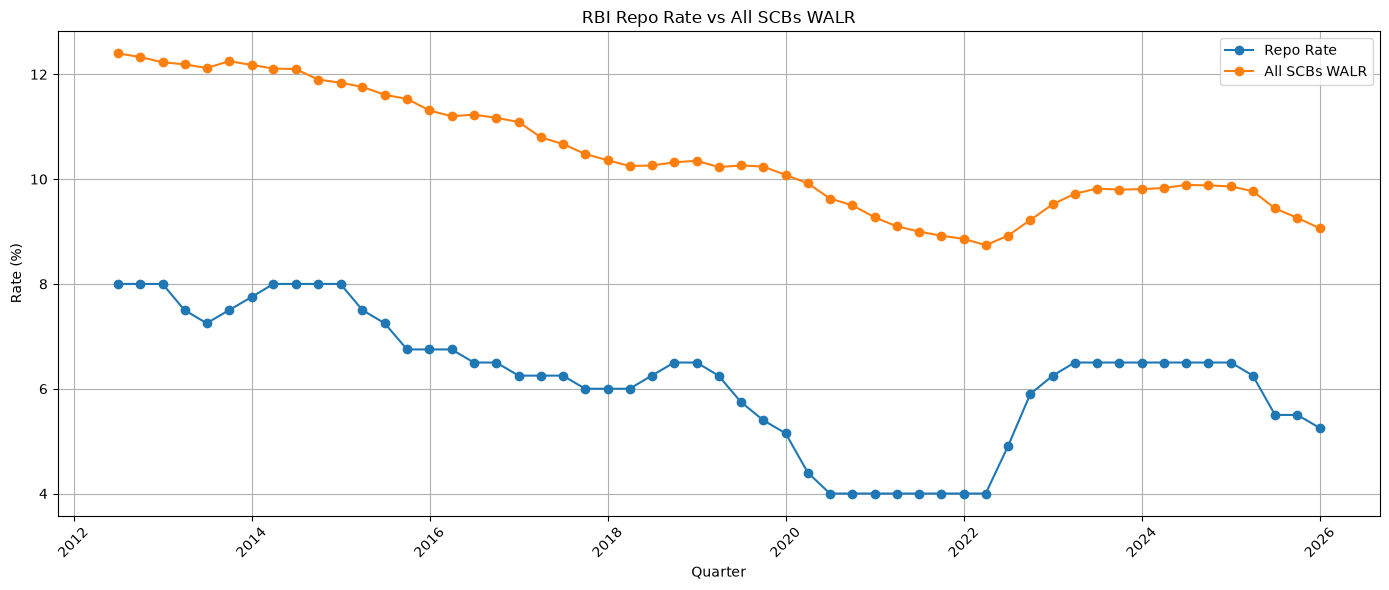

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df["Quarter"],
    analysis_df["Repo"],
    label="Repo Rate",
    marker="o"
)

plt.plot(
    analysis_df["Quarter"],
    analysis_df["All SCBs"],
    label="All SCBs WALR",
    marker="o"
)

plt.title("RBI Repo Rate vs All SCBs WALR")
plt.xlabel("Quarter")
plt.ylabel("Rate (%)")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 20. Bank Group-wise WALR Trend

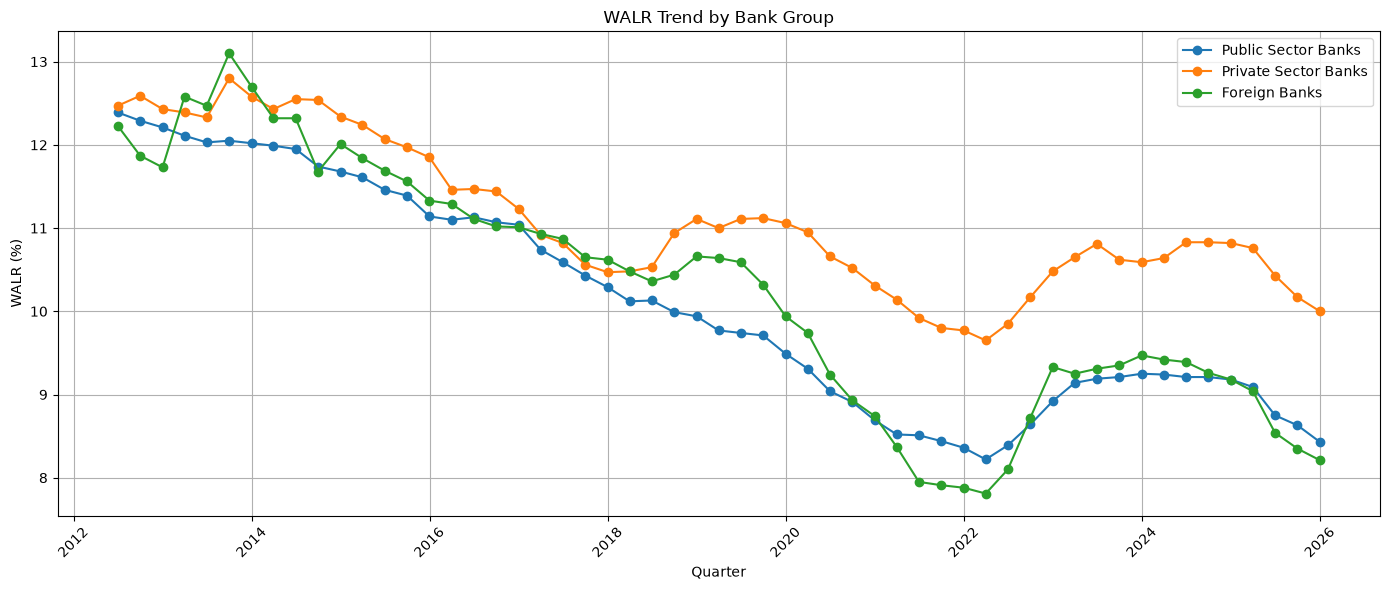

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df["Quarter"],
    analysis_df["Public Sector Banks"],
    label="Public Sector Banks",
    marker="o"
)

plt.plot(
    analysis_df["Quarter"],
    analysis_df["Private Sector Banks"],
    label="Private Sector Banks",
    marker="o"
)

plt.plot(
    analysis_df["Quarter"],
    analysis_df["Foreign Banks"],
    label="Foreign Banks",
    marker="o"
)

plt.title("WALR Trend by Bank Group")
plt.xlabel("Quarter")
plt.ylabel("WALR (%)")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 21. Correlation Analysis

In [34]:
correlation = analysis_df["Repo"].corr(
    analysis_df["All SCBs"]
)

print("Correlation between Repo Rate and All SCBs WALR:", round(correlation, 3))

Correlation between Repo Rate and All SCBs WALR: 0.856


## 22. Correlation Heatmap

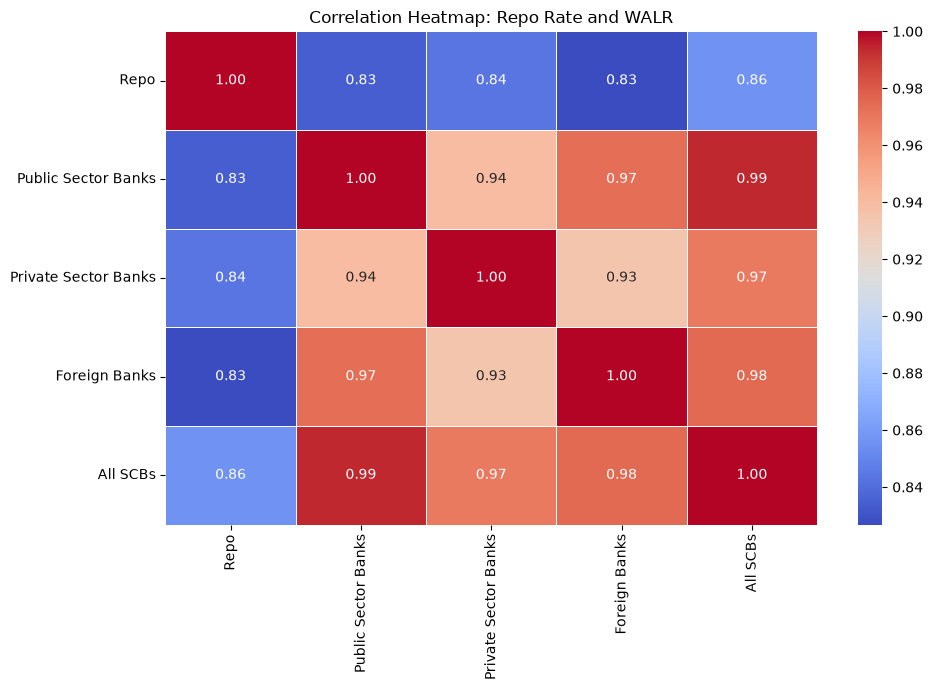

In [35]:
correlation_matrix = analysis_df[
    [
        "Repo",
        "Public Sector Banks",
        "Private Sector Banks",
        "Foreign Banks",
        "All SCBs"
    ]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap: Repo Rate and WALR")
plt.tight_layout()
plt.show()

## 23. Repo Rate vs All SCBs WALR Relationship

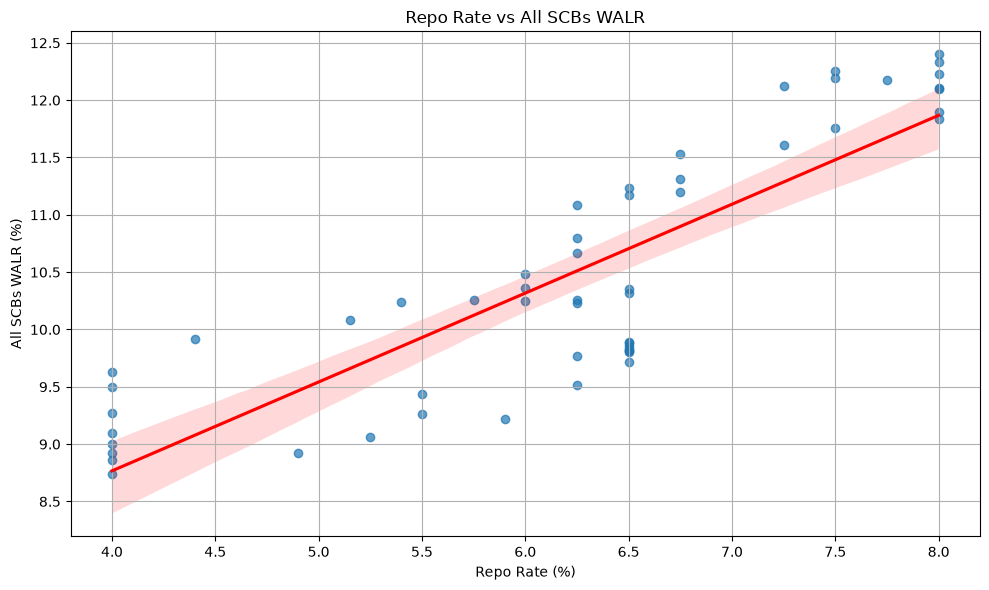

In [36]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=analysis_df,
    x="Repo",
    y="All SCBs",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Repo Rate vs All SCBs WALR")
plt.xlabel("Repo Rate (%)")
plt.ylabel("All SCBs WALR (%)")
plt.grid(True)

plt.tight_layout()
plt.show()

## 24. Quarterly Rate Changes

In [37]:
analysis_df["Repo_Change"] = analysis_df["Repo"].diff()
analysis_df["WALR_Change"] = analysis_df["All SCBs"].diff()

display(
    analysis_df[
        [
            "Quarter",
            "Repo",
            "Repo_Change",
            "All SCBs",
            "WALR_Change"
        ]
    ].head(15)
)

,Quarter,Repo,Repo_Change,All SCBs,WALR_Change
0,2012-06-30,8.00,NaN,12.40,NaN
1,2012-09-30,8.00,0.00,12.33,-0.07
2,2012-12-31,8.00,0.00,12.23,-0.10
3,2013-03-31,7.50,-0.50,12.19,-0.04
4,2013-06-30,7.25,-0.25,12.12,-0.07
5,2013-09-30,7.50,0.25,12.25,0.13
6,2013-12-31,7.75,0.25,12.18,-0.07
7,2014-03-31,8.00,0.25,12.11,-0.07
8,2014-06-30,8.00,0.00,12.10,-0.01
9,2014-09-30,8.00,0.00,11.90,-0.20


## 25. Correlation of Quarterly Rate Changes

In [38]:
change_correlation = analysis_df["Repo_Change"].corr(
    analysis_df["WALR_Change"]
)

print(
    "Correlation between Repo Rate Change and WALR Change:",
    round(change_correlation, 3)
)

Correlation between Repo Rate Change and WALR Change: 0.602


## 26. One-Quarter Lag Analysis

In [39]:
analysis_df["Repo_Change_Lag_1Q"] = analysis_df["Repo_Change"].shift(1)

lag_correlation = analysis_df["Repo_Change_Lag_1Q"].corr(
    analysis_df["WALR_Change"]
)

print(
    "Correlation between Previous Quarter Repo Rate Change and Current Quarter WALR Change:",
    round(lag_correlation, 3)
)

Correlation between Previous Quarter Repo Rate Change and Current Quarter WALR Change: 0.656


## 27. Quarterly Changes in Repo Rate and WALR

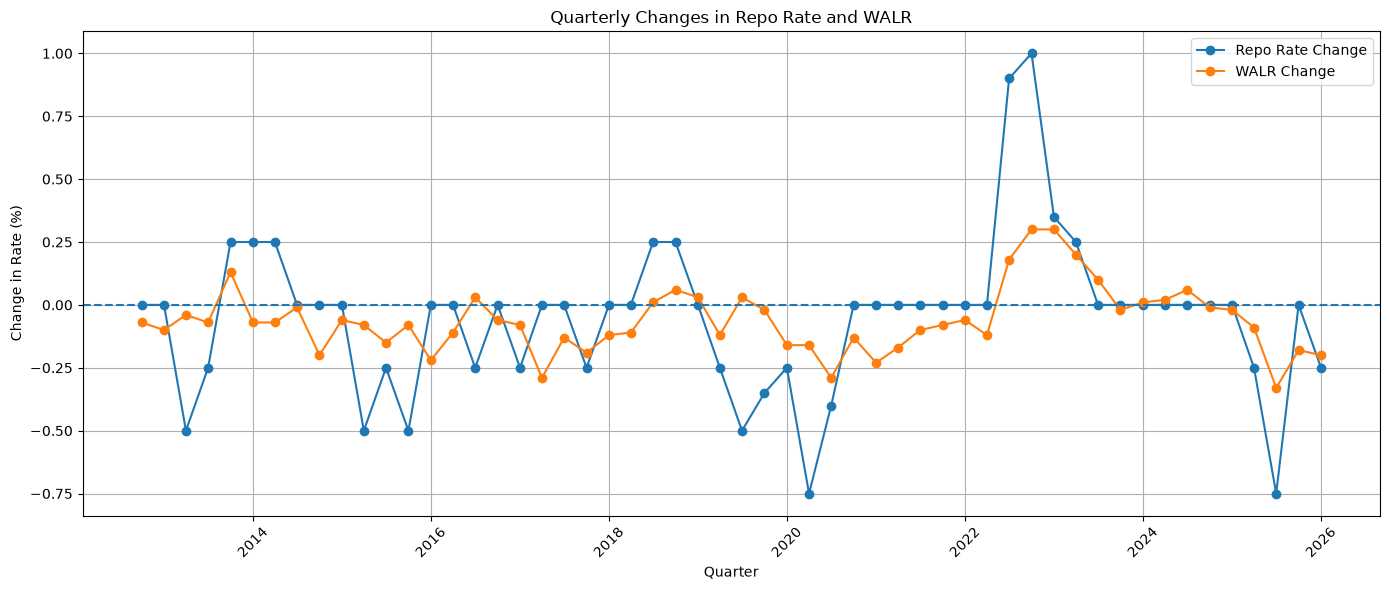

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df["Quarter"],
    analysis_df["Repo_Change"],
    label="Repo Rate Change",
    marker="o"
)

plt.plot(
    analysis_df["Quarter"],
    analysis_df["WALR_Change"],
    label="WALR Change",
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Quarterly Changes in Repo Rate and WALR")
plt.xlabel("Quarter")
plt.ylabel("Change in Rate (%)")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 28. Maximum and Minimum Rate Analysis

In [41]:
print("Repo Rate:")
print("Maximum:", analysis_df["Repo"].max())
print("Minimum:", analysis_df["Repo"].min())

print("\nAll SCBs WALR:")
print("Maximum:", analysis_df["All SCBs"].max())
print("Minimum:", analysis_df["All SCBs"].min())

Repo Rate:
Maximum: 8.0
Minimum: 4.0

All SCBs WALR:
Maximum: 12.4
Minimum: 8.74


## 29. Maximum and Minimum Rate Periods

In [42]:
repo_max = analysis_df.loc[
    analysis_df["Repo"].idxmax()
]

repo_min = analysis_df.loc[
    analysis_df["Repo"].idxmin()
]

walr_max = analysis_df.loc[
    analysis_df["All SCBs"].idxmax()
]

walr_min = analysis_df.loc[
    analysis_df["All SCBs"].idxmin()
]

print("Repo Rate:")
print("Maximum:", repo_max["Repo"], "on", repo_max["Quarter"].date())
print("Minimum:", repo_min["Repo"], "on", repo_min["Quarter"].date())

print("\nAll SCBs WALR:")
print("Maximum:", walr_max["All SCBs"], "on", walr_max["Quarter"].date())
print("Minimum:", walr_min["All SCBs"], "on", walr_min["Quarter"].date())

Repo Rate:
Maximum: 8.0 on 2012-06-30
Minimum: 4.0 on 2020-06-30

All SCBs WALR:
Maximum: 12.4 on 2012-06-30
Minimum: 8.74 on 2022-03-31


## 30. Export Cleaned Analysis Dataset

In [43]:
output_path = "../data/RBI_Repo_Rate_Analysis_Cleaned.csv"

analysis_df.to_csv(
    output_path,
    index=False
)

print("Cleaned dataset saved successfully!")
print("File:", output_path)

Cleaned dataset saved successfully!
File: ../data/RBI_Repo_Rate_Analysis_Cleaned.csv


## 31. Final Dataset Validation

In [44]:
print("Final Dataset Shape:", analysis_df.shape)

print("\nColumn Names:")
print(analysis_df.columns.tolist())

print("\nMissing Values:")
display(analysis_df.isnull().sum())

print("\nDuplicate Rows:", analysis_df.duplicated().sum())

print("\nFinal Dataset:")
display(analysis_df.head())

Final Dataset Shape: (55, 9)

Column Names:
['Quarter', 'Repo', 'Public Sector Banks', 'Private Sector Banks', 'Foreign Banks', 'All SCBs', 'Repo_Change', 'WALR_Change', 'Repo_Change_Lag_1Q']

Missing Values:


Quarter                 0
Repo                    0
Public Sector Banks     0
Private Sector Banks    0
Foreign Banks           0
All SCBs                0
Repo_Change             1
WALR_Change             1
Repo_Change_Lag_1Q      2
dtype: int64


Duplicate Rows: 0

Final Dataset:


,Quarter,Repo,Public Sector Banks,Private Sector Banks,Foreign Banks,All SCBs,Repo_Change,WALR_Change,Repo_Change_Lag_1Q
0,2012-06-30,8.00,12.39,12.47,12.23,12.40,NaN,NaN,NaN
1,2012-09-30,8.00,12.29,12.59,11.87,12.33,0.00,-0.07,NaN
2,2012-12-31,8.00,12.21,12.43,11.73,12.23,0.00,-0.10,0.0
3,2013-03-31,7.50,12.11,12.39,12.58,12.19,-0.50,-0.04,0.0
4,2013-06-30,7.25,12.03,12.33,12.47,12.12,-0.25,-0.07,-0.5


## 32. Key Analysis Summary

In [45]:
summary = {
    "Repo Rate Maximum": analysis_df["Repo"].max(),
    "Repo Rate Minimum": analysis_df["Repo"].min(),
    "WALR Maximum": analysis_df["All SCBs"].max(),
    "WALR Minimum": analysis_df["All SCBs"].min(),
    "Repo-WALR Correlation": analysis_df["Repo"].corr(
        analysis_df["All SCBs"]
    ),
    "Change Correlation": analysis_df["Repo_Change"].corr(
        analysis_df["WALR_Change"]
    ),
    "Lagged Correlation": analysis_df["Repo_Change_Lag_1Q"].corr(
        analysis_df["WALR_Change"]
    )
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Repo Rate Maximum,8.000000
1,Repo Rate Minimum,4.000000
2,WALR Maximum,12.400000
3,WALR Minimum,8.740000
4,Repo-WALR Correlation,0.855771
5,Change Correlation,0.601865
6,Lagged Correlation,0.656227


## 33. Key Findings

- The Repo Rate ranged from 4.00% to 8.00% during the analysis period.
- All SCBs WALR ranged from 8.74% to 12.40%.
- The correlation between Repo Rate and All SCBs WALR was approximately 0.856, indicating a strong positive association in the analyzed dataset.
- The correlation between quarterly Repo Rate changes and WALR changes was approximately 0.602.
- The correlation between the previous quarter's Repo Rate change and the current quarter's WALR change was approximately 0.656.
- The results indicate that changes in the Repo Rate and bank lending rates moved in a related direction during the analyzed period.
- Correlation measures association and does not by itself establish a causal relationship between Repo Rate and WALR.